# ****NEXT LEVEL MODELING****

Notebook ini menulis dan menguji Algoritma Genetika yang mencari batas interval terbaik bagi Fuzzy Time Series, lalu membandingkannya dengan pembagian interval lain pada jumlah interval yang sama.

<p align="center">
    <img src="../xLain_Lain/img/nlm_o.png" alt="Next Level Modeling" witdh="100" height="500">
</p>

---

### ****DAFTAR ISI****

0. Persiapan Lingkungan Kerja dan Pemuatan Data
1. Rancangan Algoritma Genetika
2. Pengujian Modul Algoritma Genetika
3. Satu Kali Jalan pada K = 15 dan Pembanding
4. Eksperimen Berulang pada Berbagai Jumlah Interval
5. Perbandingan dengan Model Dasar
6. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan Lingkungan Kerja dan Pemuatan Data****

#### ****0.1 Mengapa langkah ini penting?****

Seperti pada Notebook 4, notebook ini hanya memuat data latih dan data validasi. Data uji tetap tidak disentuh sampai seluruh konfigurasi model terkunci. Hasil model dasar dari Notebook 4 juga dimuat agar hasil Algoritma Genetika dapat langsung dibandingkan dengan tolok ukur yang sama.

#### ****0.2 Memuat data dan hasil model dasar****

Sel berikut memuat paket dan modul proyek, data latih dan validasi, serta tabel hasil model dasar dari folder Model.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from src.metrics import ringkas_metrik
from src.fts import interval_sama_panjang, FuzzyTimeSeriesChen
from src.ga import (mape_fts, lebar_ke_batas, perbaiki, jalankan_ga,
                    batas_kuantil, pencarian_acak)

rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

pembagian = pd.read_csv(config.DIR_CLEAN / "pembagian_data.csv", parse_dates=["tanggal"])
pembagian = pembagian[pembagian["subset"].isin(["latih", "validasi"])]
latih = pembagian[pembagian["subset"] == "latih"].set_index("tanggal")["harga"]
validasi = pembagian[pembagian["subset"] == "validasi"].set_index("tanggal")["harga"]
semua = pd.concat([latih, validasi])
acuan_validasi = semua.shift(1).loc[validasi.index]

with open(config.DIR_MODEL / "konfigurasi_baseline.json", encoding="utf-8") as f:
    konfigurasi_baseline = json.load(f)
hasil_baseline = pd.read_csv(config.DIR_MODEL / "hasil_baseline_validasi.csv", index_col=0)

print("=" * 62)
print("Data dan hasil model yang dimuat")
print("=" * 62)
print(f"Data latih : {len(latih)} hari ({latih.index.min().date()} sampai {latih.index.max().date()})")
print(f"Data validasi : {len(validasi)} hari ({validasi.index.min().date()} sampai {validasi.index.max().date()})")
print("Data uji : sengaja tidak dimuat pada notebook ini")
print()
print("MAPE validasi model dasar dari Notebook 4:")
print(hasil_baseline["MAPE_%"].round(2).to_string())

Data dan hasil model yang dimuat
Data latih : 1221 hari (2020-01-02 sampai 2024-11-06)
Data validasi : 261 hari (2024-11-07 sampai 2025-11-06)
Data uji : sengaja tidak dimuat pada notebook ini

MAPE validasi model dasar dari Notebook 4:
ARIMA(3, 1, 2)                                3.67
Regresi linear (lag=7)                        3.76
Naive                                         3.85
FTS interval sama panjang (K=150, rujukan)    4.72
Perceptron berlapis (lag=5, 16 neuron)        4.97
Moving average (k=2)                          5.22
FTS interval sama panjang (K=15)              8.51


### ****1. Rancangan Algoritma Genetika****

#### ****1.1 Mengapa langkah ini penting?****

Hasil Algoritma Genetika sangat dipengaruhi pilihan rancangan, mulai dari bentuk kromosom sampai parameter evolusi. Bila parameter disetel berulang kali sambil melihat hasil validasi, angka validasi menjadi terlalu optimistis. Karena itu seluruh rancangan di bawah ditetapkan sebelum eksperimen dijalankan dan tidak diubah mengikuti hasil.

#### ****1.2 Masalah optimasi****

Untuk jumlah interval K yang diberikan, dicari K dikurangi satu batas interior di antara harga terendah dan tertinggi data latih sehingga MAPE Fuzzy Time Series sekecil mungkin. Fungsi tujuannya bersifat patah-patah: menggeser sebuah batas sedikit kadang tidak mengubah apa pun, lalu tiba-tiba memindahkan beberapa data ke himpunan lain dan mengubah aturan. Fungsi seperti ini tidak mulus dan tidak dapat diturunkan, sehingga metode berbasis gradien tidak cocok dan pencarian berbasis populasi seperti Algoritma Genetika layak dicoba.

#### ****1.3 Rancangan****

1. Kromosom: K proporsi lebar interval yang berjumlah satu. Ujung semesta tetap (harga latih terendah dan tertinggi) dan batas diperoleh dari penjumlahan kumulatif lebar, sehingga batas selalu terurut dan menutup seluruh semesta.
2. Batasan: setiap interval minimal selebar 25% dari lebar pembagian sama panjang, agar interval tidak menyusut menjadi sempit sekali.
3. Fitness: MAPE pada data latih, yang diminimalkan. Metrik ini sama dengan metrik evaluasi.
4. Populasi awal: 60 individu, terdiri atas satu pembagian sama panjang dan 59 pembagian acak (distribusi Dirichlet).
5. Seleksi: turnamen dengan ukuran tiga.
6. Crossover: aritmetika (campuran dua induk dengan bobot acak) dengan peluang 0,9.
7. Mutasi: perubahan gaussian relatif pada tiap lebar dengan peluang 0,2 dan simpangan baku 0,25, diikuti perbaikan batasan.
8. Elitisme: dua individu terbaik dibawa ke generasi berikutnya.
9. Berhenti: setelah 150 generasi, tanpa penghentian dini yang memakai data validasi.

#### ****1.4 Pengamanan terhadap overfitting****

1. Seluruh parameter di atas ditetapkan sebelum melihat hasil validasi.
2. Data validasi tidak memengaruhi evolusi. Nilai validasi individu terbaik hanya dicatat sebagai diagnostik.
3. Data uji tidak dipakai sama sekali.
4. Karena pembagian sama panjang masuk populasi awal dan elitisme dipakai, MAPE latih hasil Algoritma Genetika tidak mungkin lebih buruk daripada pembagian sama panjang. Yang diuji adalah apakah keunggulan pada data latih bertahan pada data validasi.

#### ****1.5 Pembanding yang adil****

Pembagian sama panjang adalah pembanding yang mudah dikalahkan pada data harga yang condong ke kanan. Agar manfaat Algoritma Genetika tidak tercampur dengan manfaat sekadar tidak memakai pembagian sama panjang, hasilnya dibandingkan pada jumlah interval yang sama dengan:
1. Pembagian sama panjang.
2. Pembagian sama frekuensi (kuantil), yaitu tiap interval berisi jumlah data latih yang kira-kira sama, tanpa optimasi apa pun.
3. Pencarian acak dengan jumlah evaluasi fitness yang sama dengan Algoritma Genetika, yaitu mencoba banyak pembagian acak dan mengambil yang terbaik pada data latih.

### ****2. Pengujian Modul Algoritma Genetika****

#### ****2.1 Mengapa langkah ini penting?****

Algoritma Genetika memakai fungsi evaluasi cepat yang ditulis ulang agar ribuan evaluasi dapat dijalankan dalam waktu singkat. Bila fungsi cepat itu berbeda sedikit saja dari kelas Fuzzy Time Series yang sudah diuji, seluruh hasil optimasi menjadi tidak dapat dipercaya. Karena itu modul diuji dulu sebelum dipakai.

#### ****2.2 Yang diuji****

Sel berikut memeriksa tiga hal:
1. Fungsi evaluasi cepat menghasilkan MAPE validasi yang sama persis dengan kelas Fuzzy Time Series pada K = 7, 10, 15, dan 20.
2. Fungsi perbaikan menghasilkan lebar yang berjumlah satu dan memenuhi lebar minimum, serta konversi ke batas menghasilkan batas yang menaik tegas dengan ujung yang benar.
3. Batas berfrekuensi sama menaik tegas dan menghasilkan jumlah data per interval yang hampir sama.

In [ ]:
def periksa(nama, lulus, rincian=""):
    print(f"[{'LULUS  ' if lulus else 'PERIKSA'}] {nama}" + (f" -> {rincian}" if rincian else ""))

d = latih.values

print("=" * 62)
print("Uji 1: Fungsi cepat sama dengan kelas FTS")
print("=" * 62)
for K in (7, 10, 15, 20):
    b = interval_sama_panjang(d, K)
    model = FuzzyTimeSeriesChen(b).fit(d)
    mape_kelas = float(np.mean(np.abs(validasi.values - model.ramal(acuan_validasi.values)) / validasi.values) * 100)
    mape_cepat = mape_fts(b, d, acuan_validasi.values, validasi.values)
    periksa(f"K = {K:<2} MAPE validasi sama", abs(mape_kelas - mape_cepat) < 1e-9,
            f"kelas {mape_kelas:.6f}, cepat {mape_cepat:.6f}")

print()
print("=" * 62)
print("Uji 2: Perbaikan lebar interval dan konversi ke batas")
print("=" * 62)
rng = np.random.default_rng(0)
mentah = rng.random((1000, 15)) * rng.random((1000, 15)) ** 3
diperbaiki = perbaiki(mentah, 0.25 / 15)
periksa("Jumlah proporsi setiap kromosom tepat 1", bool(np.allclose(diperbaiki.sum(axis=1), 1)))
periksa("Setiap lebar >= 25% dari lebar sama panjang", bool((diperbaiki >= 0.25 / 15 - 1e-12).all()))
batas_uji = lebar_ke_batas(diperbaiki[0], d.min(), d.max())
periksa("Batas menaik tegas", bool(np.all(np.diff(batas_uji) > 0)))
periksa("Ujung batas sama dengan harga latih terendah dan tertinggi",
        bool(batas_uji[0] == d.min() and np.isclose(batas_uji[-1], d.max())))

print()
print("=" * 62)
print("Uji 3: Batas berfrekuensi sama")
print("=" * 62)
for K in (7, 10, 15, 20):
    b = batas_kuantil(d, K)
    jumlah = np.histogram(d, bins=b)[0]
    periksa(f"K = {K:<2} batas menaik tegas", bool(np.all(np.diff(b) > 0)),
            f"data per interval {jumlah.min()} sampai {jumlah.max()}")

Uji 1: Fungsi cepat sama dengan kelas FTS
[LULUS  ] K = 7  MAPE validasi sama -> kelas 12.147826, cepat 12.147826
[LULUS  ] K = 10 MAPE validasi sama -> kelas 8.772744, cepat 8.772744
[LULUS  ] K = 15 MAPE validasi sama -> kelas 8.510537, cepat 8.510537
[LULUS  ] K = 20 MAPE validasi sama -> kelas 9.135083, cepat 9.135083

Uji 2: Perbaikan lebar interval dan konversi ke batas
[LULUS  ] Jumlah proporsi setiap kromosom tepat 1
[LULUS  ] Setiap lebar >= 25% dari lebar sama panjang
[LULUS  ] Batas menaik tegas
[LULUS  ] Ujung batas sama dengan harga latih terendah dan tertinggi

Uji 3: Batas berfrekuensi sama
[LULUS  ] K = 7  batas menaik tegas -> data per interval 174 sampai 175
[LULUS  ] K = 10 batas menaik tegas -> data per interval 121 sampai 123
[LULUS  ] K = 15 batas menaik tegas -> data per interval 79 sampai 83
[LULUS  ] K = 20 batas menaik tegas -> data per interval 59 sampai 63


### ****3. Satu Kali Jalan pada K = 15 dan Pembanding****

#### ****3.1 Mengapa langkah ini penting?****

Sebelum menjalankan puluhan kali pengulangan, kami menjalankan sekali dulu untuk melihat perilaku algoritma: apakah kesalahan benar-benar turun selama evolusi, apakah batas yang dihasilkan masuk akal, dan bagaimana hasilnya dibandingkan pembagian lain. Satu kali jalan belum cukup untuk menarik kesimpulan karena Algoritma Genetika bersifat acak. Kesimpulan baru dibuat dari eksperimen berulang pada bagian 4.

#### ****3.2 Yang dilakukan****

Dua sel berikut:
1. Menjalankan Algoritma Genetika pada K = 15 dengan seed tetap, lalu membandingkannya dengan pembagian sama panjang, sama frekuensi, dan pencarian acak. Grafik kiri menampilkan kurva evolusi, dan grafik kanan menampilkan batas hasil optimasi pada sebaran data latih.
2. Menampilkan seluruh aturan fuzzy hasil optimasi dan mengukur modelnya pada data validasi memakai kelas Fuzzy Time Series.

SATU KALI JALAN PADA K = 15 (seed 42)
                              MAPE_latih_%  MAPE_validasi_%  lebar_interval_min  lebar_interval_maks
Sama panjang                         10.59             8.51             6476.67              6476.67
Sama frekuensi (kuantil)              8.05             6.87             2266.67             31366.67
Pencarian acak (9000 sampel)          6.93             7.01             1619.17             12780.22
Algoritma Genetika                    6.07             6.32             2085.46             11362.60

Jumlah evaluasi fitness: Algoritma Genetika 9060, pencarian acak 9000


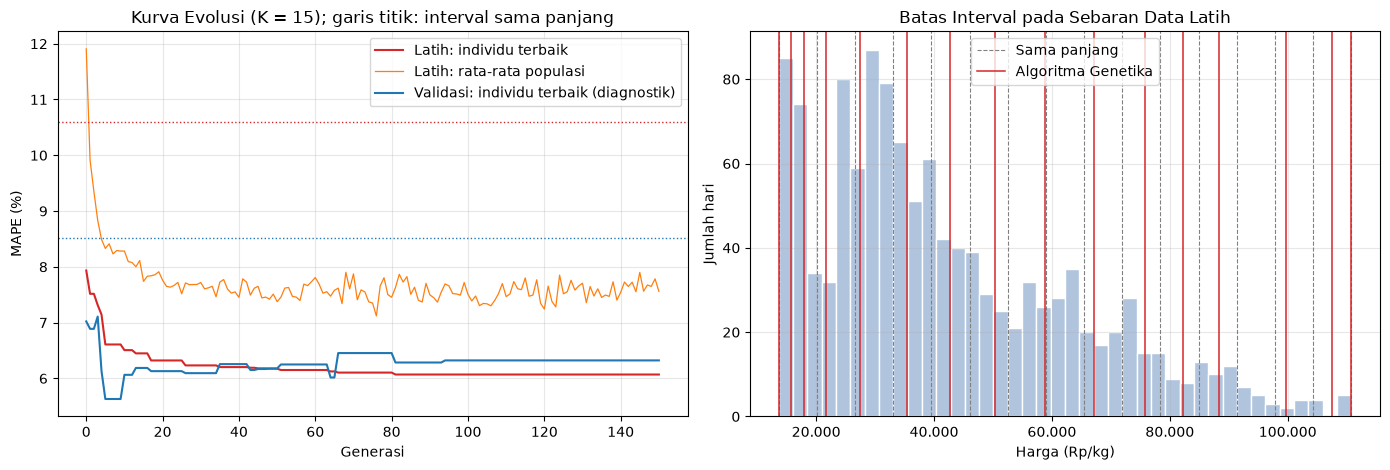

In [3]:
K_CONTOH = 15
UKURAN_POPULASI, JUMLAH_GENERASI = 60, 150
a_lat, y_lat = latih.values[:-1], latih.values[1:]
a_val, y_val = acuan_validasi.values, validasi.values

hasil_ga = jalankan_ga(latih.values, K_CONTOH, validasi.values, acuan_validasi.values,
                       ukuran_populasi=UKURAN_POPULASI, jumlah_generasi=JUMLAH_GENERASI, seed=config.SEED)
acak = pencarian_acak(latih.values, K_CONTOH, UKURAN_POPULASI * JUMLAH_GENERASI, seed=config.SEED)

metode = {
    "Sama panjang": interval_sama_panjang(latih.values, K_CONTOH),
    "Sama frekuensi (kuantil)": batas_kuantil(latih.values, K_CONTOH),
    f"Pencarian acak ({UKURAN_POPULASI * JUMLAH_GENERASI} sampel)": acak["batas"],
    "Algoritma Genetika": hasil_ga["batas"],
}
tabel = pd.DataFrame({
    nama: {
        "MAPE_latih_%": mape_fts(b, latih.values, a_lat, y_lat),
        "MAPE_validasi_%": mape_fts(b, latih.values, a_val, y_val),
        "lebar_interval_min": np.diff(b).min(),
        "lebar_interval_maks": np.diff(b).max(),
    }
    for nama, b in metode.items()
}).T

print("=" * 62)
print(f"SATU KALI JALAN PADA K = {K_CONTOH} (seed {config.SEED})")
print("=" * 62)
print(tabel.round(2).to_string())
print()
print(f"Jumlah evaluasi fitness: Algoritma Genetika {UKURAN_POPULASI * (JUMLAH_GENERASI + 1)}, "
      f"pencarian acak {UKURAN_POPULASI * JUMLAH_GENERASI}")

riwayat = hasil_ga["riwayat"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(riwayat.index, riwayat["mape_latih_terbaik"], color="tab:red", label="Latih: individu terbaik")
ax[0].plot(riwayat.index, riwayat["mape_latih_rata2"], color="tab:orange", linewidth=0.9, label="Latih: rata-rata populasi")
ax[0].plot(riwayat.index, riwayat["mape_validasi_terbaik"], color="tab:blue", label="Validasi: individu terbaik (diagnostik)")
ax[0].axhline(tabel.loc["Sama panjang", "MAPE_latih_%"], color="tab:red", linestyle=":", linewidth=1)
ax[0].axhline(tabel.loc["Sama panjang", "MAPE_validasi_%"], color="tab:blue", linestyle=":", linewidth=1)
ax[0].set_title(f"Kurva Evolusi (K = {K_CONTOH}); garis titik: interval sama panjang")
ax[0].set_xlabel("Generasi")
ax[0].set_ylabel("MAPE (%)")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].hist(latih, bins=40, color="lightsteelblue", edgecolor="white")
for i, b in enumerate(metode["Sama panjang"]):
    ax[1].axvline(b, color="gray", linestyle="--", linewidth=0.8, label="Sama panjang" if i == 0 else None)
for i, b in enumerate(hasil_ga["batas"]):
    ax[1].axvline(b, color="tab:red", linewidth=1.1, label="Algoritma Genetika" if i == 0 else None)
ax[1].set_title("Batas Interval pada Sebaran Data Latih")
ax[1].set_xlabel("Harga (Rp/kg)")
ax[1].set_ylabel("Jumlah hari")
ax[1].xaxis.set_major_formatter(rupiah)
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.savefig(config.DIR_IMG / "5_satu_kali_jalan_K15.png", dpi=150)
plt.show()

In [4]:
model_ga = FuzzyTimeSeriesChen(hasil_ga["batas"]).fit(latih.values)
pred_ga = pd.Series(model_ga.ramal(acuan_validasi.values), index=validasi.index)
metrik_ga = ringkas_metrik(validasi, pred_ga)

print("=" * 62)
print(f"Aturan FTS hasil GA (K = {K_CONTOH}, data latih)")
print("=" * 62)
print(model_ga.tabel_aturan().round(0).to_string())
print()
print("Metrik pada data validasi (model dari kelas, bukan fungsi cepat):")
for nama, nilai in metrik_ga.items():
    print(f"  {nama:<8}: {nilai:,.2f}")
print()
print(f"Himpunan tanpa aturan : {int((model_ga.jumlah_transisi == 0).sum())}")
print(f"Data per himpunan : minimum {int(model_ga.jumlah_data.min())}, maksimum {int(model_ga.jumlah_data.max())}")

Aturan FTS hasil GA (K = 15, data latih)
          batas_bawah  batas_atas  jumlah_data  jumlah_transisi                 tujuan  titik_ramal
himpunan                                                                                           
A1            13650.0     15735.0           74               74                 A1, A2      15757.0
A2            15735.0     17906.0           71               71             A1, A2, A3      17102.0
A3            17906.0     21678.0           61               61             A2, A3, A4      20378.0
A4            21678.0     27361.0          140              140             A3, A4, A5      25231.0
A5            27361.0     35402.0          248              247             A4, A5, A6      31648.0
A6            35402.0     42686.0          154              154             A5, A6, A7      38982.0
A7            42686.0     50355.0          114              114     A5, A6, A7, A8, A9      46900.0
A8            50355.0     58837.0           92             